# 3. A setup the model knows

First the easy case: the model is trained on some surfaces of Cluster and tested on **other surfaces of Cluster**.
Same machine, same sensors, new surfaces.

All the recordings of a surface stay on the same side (training or test), otherwise the model could just
recognize the surface.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch import nn

FAMILIES = ["wood", "metal", "textile", "polymer"]
device = "cuda" if torch.cuda.is_available() else "cpu"

## The data

The spectral shapes of `2_signals.ipynb`: third-octave levels of the sound and of the vibration, mean removed.
Here the machine lines are left in.

In [2]:
table = pd.read_csv("cache/spectral_shapes.csv", dtype={"surface": str})
bands = {
    "sound": [c for c in table.columns if c.startswith("sound ")],
    "vibration": [c for c in table.columns if c.startswith("vibration ")],
}
bands["sound + vibration"] = bands["sound"] + bands["vibration"]
cluster = table[table.dataset == "cluster"].reset_index(drop=True)
lmt108 = table[table.dataset == "lmt108"].reset_index(drop=True)

# five groups of surfaces, with the same share of each family in every group
surfaces = cluster[["surface", "family"]].drop_duplicates().reset_index(drop=True)
fold_of_surface = {}
for fold, (_, test) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(surfaces.surface, surfaces.family)):
    for surface in surfaces.surface[test]:
        fold_of_surface[surface] = fold
cluster["fold"] = cluster.surface.map(fold_of_surface)
cluster.groupby("fold").surface.nunique()

fold
0    15
1    15
2    14
3    14
4    14
Name: surface, dtype: int64

## Two simple classifiers on the spectral shapes

In [3]:
models = {
    "logistic regression": lambda: LogisticRegression(class_weight="balanced", max_iter=2000),
    "SVM": lambda: SVC(class_weight="balanced"),
}

rows = []
for name, make in models.items():
    for signal_name, columns in bands.items():
        answers = np.empty(len(cluster), dtype=object)
        for fold in range(5):
            test = (cluster.fold == fold).to_numpy()
            model = make_pipeline(StandardScaler(), make()).fit(cluster.loc[~test, columns], cluster.family[~test])
            answers[test] = model.predict(cluster.loc[test, columns])
        # trained on all of Cluster, tested on the other dataset
        model = make_pipeline(StandardScaler(), make()).fit(cluster[columns], cluster.family)
        rows.append(
            {
                "model": name,
                "signal": signal_name,
                "new surfaces of Cluster": balanced_accuracy_score(cluster.family, answers),
                "LMT108": balanced_accuracy_score(lmt108.family, model.predict(lmt108[columns])),
            }
        )
simple = pd.DataFrame(rows)
simple.round(2)

,model,signal,new surfaces of Cluster,LMT108
0,logistic regression,sound,0.59,0.29
1,logistic regression,vibration,0.39,0.29
2,logistic regression,sound + vibration,0.62,0.28
3,SVM,sound,0.68,0.29
4,SVM,vibration,0.62,0.31
5,SVM,sound + vibration,0.74,0.28


## A small CNN on spectrograms

Instead of one spectrum per recording, the CNN sees small spectrograms (0.5 s): a mel spectrogram of the sound
and a spectrogram of the vibration. One branch per signal, four convolution layers each.
The answer for a recording is the mean over its windows.

In [4]:
saved = np.load("cache/spectrograms.npz")
images = {"sound": torch.tensor(saved["audio"]), "vibration": torch.tensor(saved["accel"])}
recording_of_window = saved["recording"]
everything = pd.read_csv("cache/spectral_shapes.csv", dtype={"surface": str})[["dataset", "surface", "family"]]
family_of_window = torch.tensor(everything.family.map(FAMILIES.index).to_numpy()[recording_of_window])
fold_of_window = everything.surface.map(fold_of_surface).to_numpy()[recording_of_window]
in_cluster = (everything.dataset == "cluster").to_numpy()[recording_of_window]


def branch():
    layers = [nn.BatchNorm2d(1)]
    for a, b in [(1, 16), (16, 32), (32, 64), (64, 64)]:
        layers += [nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten())


class SmallCNN(nn.Module):
    def __init__(self, signals):
        super().__init__()
        self.signals = signals
        self.branches = nn.ModuleDict({s: branch() for s in signals})
        self.last = nn.Sequential(nn.Dropout(0.3), nn.Linear(64 * len(signals), 4))

    def forward(self, windows):
        parts = [self.branches[s](images[s][windows].float().unsqueeze(1).to(device)) for s in self.signals]
        return self.last(torch.cat(parts, dim=1))


def train_cnn(signals, windows, seed):
    torch.manual_seed(seed)
    model = SmallCNN(signals).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    # every family counts the same
    weight = 1 / torch.bincount(family_of_window[windows], minlength=4).float()
    for _ in range(2000):
        batch = windows[torch.randint(len(windows), (256,))]
        loss = nn.functional.cross_entropy(model(batch), family_of_window[batch].to(device), weight=weight.to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model.eval()


def answers_of(model, windows):
    with torch.no_grad():
        chances = torch.cat([model(windows[i : i + 1024]).softmax(dim=1).cpu() for i in range(0, len(windows), 1024)])
    per_recording = pd.DataFrame(chances.numpy(), columns=FAMILIES).groupby(recording_of_window[windows]).mean()
    return per_recording.idxmax(axis=1)

In [5]:
rows = []
for signal_name, signals in [("sound", ["sound"]), ("vibration", ["vibration"]), ("sound + vibration", ["sound", "vibration"])]:
    answers = []
    for fold in range(5):
        train = torch.tensor(np.flatnonzero(in_cluster & (fold_of_window != fold)))
        test = torch.tensor(np.flatnonzero(in_cluster & (fold_of_window == fold)))
        answers.append(answers_of(train_cnn(signals, train, seed=fold), test))
    answers = pd.concat(answers)
    model = train_cnn(signals, torch.tensor(np.flatnonzero(in_cluster)), seed=5)
    other = answers_of(model, torch.tensor(np.flatnonzero(~in_cluster)))
    rows.append(
        {
            "model": "small CNN",
            "signal": signal_name,
            "new surfaces of Cluster": balanced_accuracy_score(everything.family[answers.index], answers),
            "LMT108": balanced_accuracy_score(everything.family[other.index], other),
        }
    )
scores = pd.concat([simple, pd.DataFrame(rows)], ignore_index=True)
scores.to_csv("results/known_setup_scores.csv", index=False)
scores.round(2)

,model,signal,new surfaces of Cluster,LMT108
0,logistic regression,sound,0.59,0.29
1,logistic regression,vibration,0.39,0.29
2,logistic regression,sound + vibration,0.62,0.28
3,SVM,sound,0.68,0.29
4,SVM,vibration,0.62,0.31
5,SVM,sound + vibration,0.74,0.28
6,small CNN,sound,0.67,0.27
7,small CNN,vibration,0.66,0.25
8,small CNN,sound + vibration,0.73,0.29


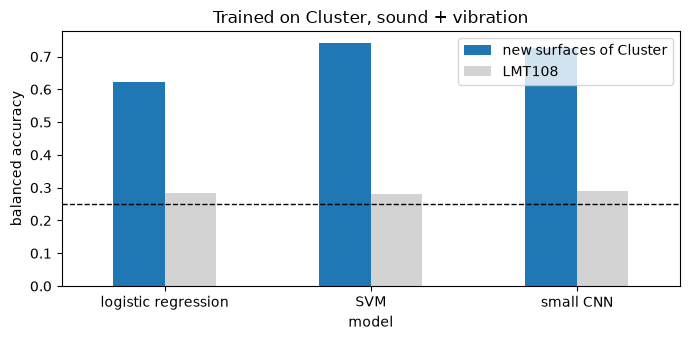

In [6]:
both = scores[scores.signal == "sound + vibration"].set_index("model")[["new surfaces of Cluster", "LMT108"]]
ax = both.plot.bar(figsize=(7, 3.5), color=["tab:blue", "lightgrey"])
ax.axhline(0.25, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("balanced accuracy")
ax.set_title("Trained on Cluster, sound + vibration")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("results/known_setup_scores.png", dpi=120)

## What we see

- On new surfaces of Cluster the SVM and the CNN reach about 0.74 with sound + vibration. Sound alone does
  better than vibration alone, and both together do best.
- The same models tested on LMT108 fall to chance. This is the real problem of the project, and the subject of
  the next notebooks.